# Cell types and adhesion affinities

Every cell belongs to a **cell type**. The type says what the elements of the cell are like and how strongly
the cell sticks to others.

| Parameter of a type | Symbol | Meaning |
|---|---|---|
| `equilibrium_distance` | $r_t$ | distance at which two elements of the type are at rest; an element is a sphere of radius $r_t/2$ |
| `intra_well_depth` | $u_t$ | depth of the well between two elements of the same cell: how stiff the cell is |
| `inter_well_depth` | $c_t$ | depth of the well between two cells of the type: how hard they are to push into each other |
| `drag_coefficient` | $\eta_t$ | drag of one element |
| `adhesion_affinities` | $a_{ts}$ | between 0 and 1, one per type: how much of the attraction to a cell of type $s$ is used |

`scale_to_elements` computes $r_t$, $u_t$, $c_t$ and $\eta_t$ from the radius, stiffness and damping of a cell and
its number of elements (see the cell scaling notebook).

## Three kinds of pairs

| Two elements of ... | Equilibrium distance | Well depth | Attraction is multiplied by |
|---|---|---|---|
| the same cell (type $t$) | $r_t$ | $u_t$ | 1 |
| two cells of the same type $t$ | $r_t$ | $c_t$ | $a_{tt}$ |
| two cells of the types $t$ and $s$ | $(r_t + r_s)/2$ | $\sqrt{c_t\,c_s}$ | $\sqrt{a_{ts}\,a_{st}}$ |

The mixed equilibrium distance is the sum of the two element radii. The geometric means are those of
PhysiCell; they give one value for the pair whatever the two affinity entries are, so action equals reaction.

## What an affinity does

An affinity weights **only the attractive side** of the potential:

- closer than the equilibrium distance, two elements repel in full;
- further apart, their attraction is multiplied by the affinity.

The force is zero at the equilibrium distance in both cases, so it has no jump and the equilibrium distance
does not move. An affinity of 1 is the plain potential; an affinity of 0 leaves a purely repulsive contact, so
cells that do not stick still cannot overlap. (Scaling the whole well instead would also remove the
repulsion, and such cells would pass through each other.)

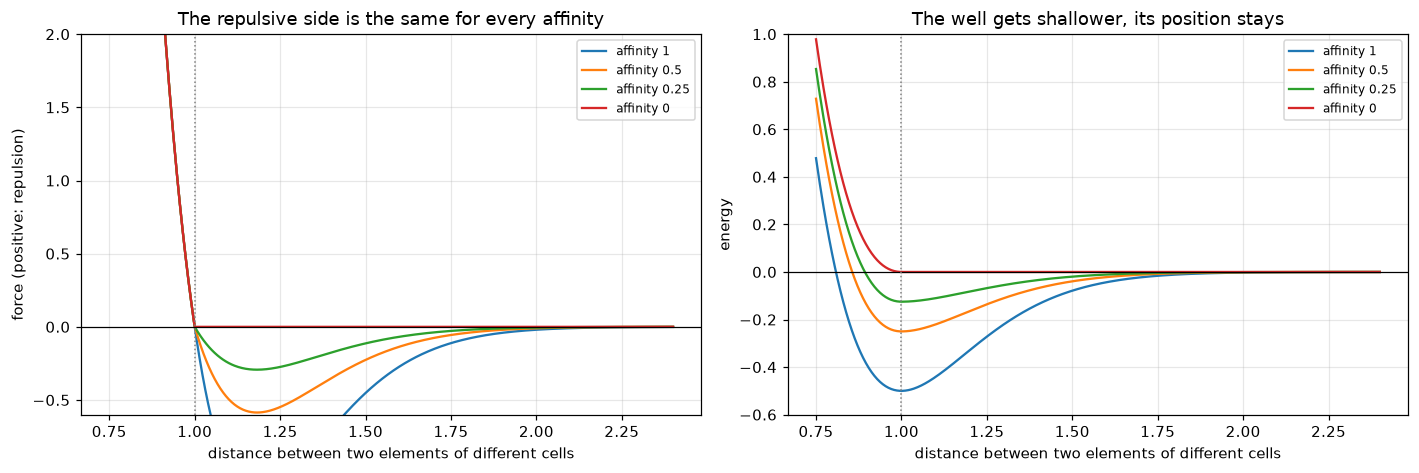

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def pair_force(r, well_depth=0.5, equilibrium_distance=1.0, steepness=2.0, affinity=1.0):
    # radial force between two elements of different cells, positive = repulsion
    t = np.exp(steepness * (1 - (r / equilibrium_distance) ** 2))
    force = 4 * well_depth * steepness / equilibrium_distance**2 * t * (t - 1) * r
    return np.where(force < 0, affinity * force, force)


def pair_energy(r, well_depth=0.5, equilibrium_distance=1.0, steepness=2.0, affinity=1.0):
    t = np.exp(steepness * (1 - (r / equilibrium_distance) ** 2))
    energy = well_depth * t * (t - 2)
    return np.where(r >= equilibrium_distance, affinity * energy, energy + (1 - affinity) * well_depth)


r = np.linspace(0.75, 2.4, 600)
fig, (ax_force, ax_energy) = plt.subplots(1, 2, figsize=(13, 4.4))
for affinity in (1.0, 0.5, 0.25, 0.0):
    ax_force.plot(r, pair_force(r, affinity=affinity), label=f"affinity {affinity:g}")
    ax_energy.plot(r, pair_energy(r, affinity=affinity), label=f"affinity {affinity:g}")

    # the energy is continuous and the force is minus its derivative, also across the minimum
    slope = -np.gradient(pair_energy(r, affinity=affinity), r)
    assert np.allclose(pair_force(r, affinity=affinity)[2:-2], slope[2:-2], rtol=0.02, atol=0.02)

for ax, name in ((ax_force, "force (positive: repulsion)"), (ax_energy, "energy")):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(1.0, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="distance between two elements of different cells", ylabel=name)
    ax.legend(fontsize=8)
ax_force.set(ylim=(-0.6, 2.0), title="The repulsive side is the same for every affinity")
ax_energy.set(ylim=(-0.6, 1.0), title="The well gets shallower, its position stays")
fig.tight_layout()

The energy needed to pull two elements apart is the affinity times the well depth. Calibrating adhesion
between two types is therefore one number per pair of types, and it does not change how the cells resist
compression.

## Cell sorting

The classic test of differential adhesion (Steinberg 1963): mix two kinds of cells that prefer their own kind,
let them rearrange, and they sort.

Cells of 19 elements start as a block in which the two types are assigned at random. Cells of the same type
stick with the affinity 1; the affinity between the two types is lower. A box with walls keeps them together.

**The measure.** For every cell, take its nearest cells by the distance between centres (6 in 2D, 12 in 3D)
and count the fraction that is of the other type; average over all cells. It asks who is next to whom, not
whether they touch. That matters: unlike cells that do not stick stop *touching* almost at once, long before
any cell has changed place, so a measure based on contacts falls much faster and overstates the sorting. The
example prints both; only the nearest-neighbour measure is used below.

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.cell_sorting
D=mechanics/micromechanics/docs/notebooks/data
for a in 0.1 0.5 1; do $E $a 200 > $D/cell_sorting_$a.csv; done
for kT in 0 0.05 0.1 0.2 0.3; do $E 0.1 200 dims=3 speed=0 kT=$kT > $D/cell_sorting_3d_kT_$kT.csv; done
for s in 2 4; do $E 0.1 200 dims=3 speed=0 kT=0.1 stiffness=$s > $D/cell_sorting_3d_stiffness_$s.csv; done
$E 1 200 dims=3 speed=0 kT=0.1 > $D/cell_sorting_3d_control.csv
for kT in 0 0.2 0.3; do $E 0.1 200 dims=3 speed=0 box=6 kT=$kT > $D/cell_sorting_3d_packed_kT_$kT.csv; done
$E 1 200 dims=3 speed=0 box=6 kT=0.3 > $D/cell_sorting_3d_packed_control.csv
```

The 3D runs take about ten minutes each in a debug build, the one with stiffness 4 four times as long.

In [2]:
def load(name):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = {key: float(value) for key, value in (item.split("=") for item in header)}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1)


def late(table):
    # mean of the measure over the last quarter of the run
    return table["unlike_nearest_fraction"][table["time"] >= 150].mean()

### In 2D, with crawling cells

36 cells in a sheet, crawling in random directions (migration speed 0.3), no noise.

affinity    1: starts at 0.51, last quarter of the run 0.48
affinity  0.5: starts at 0.51, last quarter of the run 0.43
affinity  0.1: starts at 0.51, last quarter of the run 0.39


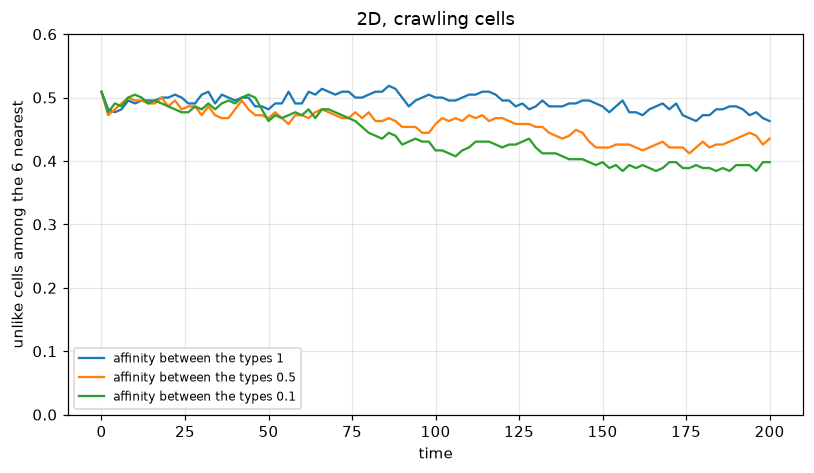

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ends = {}
for affinity in ("1", "0.5", "0.1"):
    params, table = load(f"cell_sorting_{affinity}.csv")
    ax.plot(table["time"], table["unlike_nearest_fraction"], label=f"affinity between the types {affinity}")
    ends[affinity] = late(table)
    print(f"affinity {affinity:>4}: starts at {table['unlike_nearest_fraction'][0]:.2f}, last quarter of the run {ends[affinity]:.2f}")

ax.set(xlabel="time", ylabel="unlike cells among the 6 nearest", ylim=(0, 0.6), title="2D, crawling cells")
ax.legend(fontsize=8)
fig.tight_layout()

assert ends["0.1"] < ends["0.5"] < ends["1"], "the lower the affinity between the types, the more they sort"
assert ends["0.1"] < 0.42 and ends["1"] > 0.45

### In 3D, with thermal noise

64 cells in a 4 x 4 x 4 block, no crawling. What lets the cells rearrange here is the thermal noise on their
elements, set by the thermal energy $kT$ (compare with the well depths: 1 inside a cell, 0.5 between cells).

Two questions:

- **Does more noise sort better?** $kT$ from 0 to 0.3.
- **Do stiffer cells sort less?** The well depth inside the cell from 1 to 4, at $kT = 0.1$. The well between
  cells stays at 0.5, so the cells stick equally and only differ in how easily they deform.

The output also counts **strayed elements**, further than 4 from the centre of their cell: a sign that the
noise is tearing cells apart.

run                          last quarter   strayed elements at the end
control (equal affinities)           0.45                             1
kT = 0                               0.30                             0
kT = 0.05                            0.29                             0
kT = 0.1                             0.32                             0
kT = 0.2                             0.22                             1
kT = 0.3                             0.19                            10
stiffness 2, kT = 0.1                0.34                             0
stiffness 4, kT = 0.1                0.35                             0


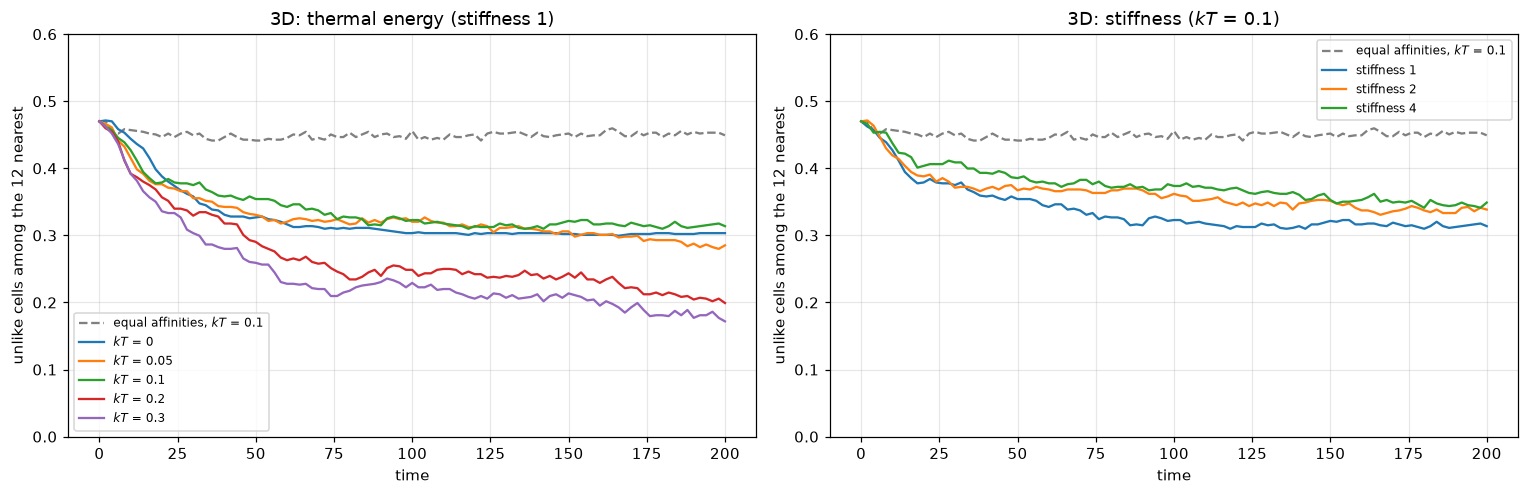

In [4]:
fig, (ax_noise, ax_stiff) = plt.subplots(1, 2, figsize=(14, 4.6))

params, control = load("cell_sorting_3d_control.csv")
for ax in (ax_noise, ax_stiff):
    ax.plot(control["time"], control["unlike_nearest_fraction"], color="gray", linestyle="--", label="equal affinities, $kT$ = 0.1")

print(f"{'run':<28}{'last quarter':>13}{'strayed elements at the end':>30}")
print(f"{'control (equal affinities)':<28}{late(control):>13.2f}{int(control['stray_elements'][-1]):>30}")

noise = {}
for kT in ("0", "0.05", "0.1", "0.2", "0.3"):
    params, table = load(f"cell_sorting_3d_kT_{kT}.csv")
    ax_noise.plot(table["time"], table["unlike_nearest_fraction"], label=f"$kT$ = {kT}")
    noise[kT] = late(table)
    print(f"{'kT = ' + kT:<28}{noise[kT]:>13.2f}{int(table['stray_elements'][-1]):>30}")

stiff = {"1": noise["0.1"]}
params, table = load("cell_sorting_3d_kT_0.1.csv")
ax_stiff.plot(table["time"], table["unlike_nearest_fraction"], label="stiffness 1")
for stiffness in ("2", "4"):
    params, table = load(f"cell_sorting_3d_stiffness_{stiffness}.csv")
    ax_stiff.plot(table["time"], table["unlike_nearest_fraction"], label=f"stiffness {stiffness}")
    stiff[stiffness] = late(table)
    print(f"{'stiffness ' + stiffness + ', kT = 0.1':<28}{stiff[stiffness]:>13.2f}{int(table['stray_elements'][-1]):>30}")
    assert table["stray_elements"].max() == 0, "stiffer cells must not fall apart"

ax_noise.set(xlabel="time", ylabel="unlike cells among the 12 nearest", ylim=(0, 0.6), title="3D: thermal energy (stiffness 1)")
ax_stiff.set(xlabel="time", ylabel="unlike cells among the 12 nearest", ylim=(0, 0.6), title="3D: stiffness ($kT$ = 0.1)")
ax_noise.legend(fontsize=8)
ax_stiff.legend(fontsize=8)
fig.tight_layout()

assert late(control) > 0.42, "with equal affinities the cells stay mixed"
assert max(noise.values()) < 0.35, "with a low affinity between the types the cells sort at every temperature"
assert noise["0.3"] < noise["0.2"] < min(noise["0"], noise["0.05"], noise["0.1"]) - 0.03, "strong noise sorts further"
assert stiff["1"] < stiff["2"] < stiff["4"] + 0.02, "stiffer cells do not sort better"

### In 3D, packed

In the runs above the box is 22 wide for a block of cells about 14 wide: the cells fill less than a tenth of it.
Cells that do not stick can then simply drift apart, which lowers the measure without any cell squeezing past
another. With `box=6` the box is 12 wide and the cells fill about half of it by their nominal volume. They
cannot get away from each other, so a fall of the measure means that cells have changed places.

thermal energy    packed box  open box  strayed, packed
0                       0.37      0.30                0
0.2                     0.20      0.22                2
0.3                     0.19      0.19                8
control, 0.3            0.51                         13


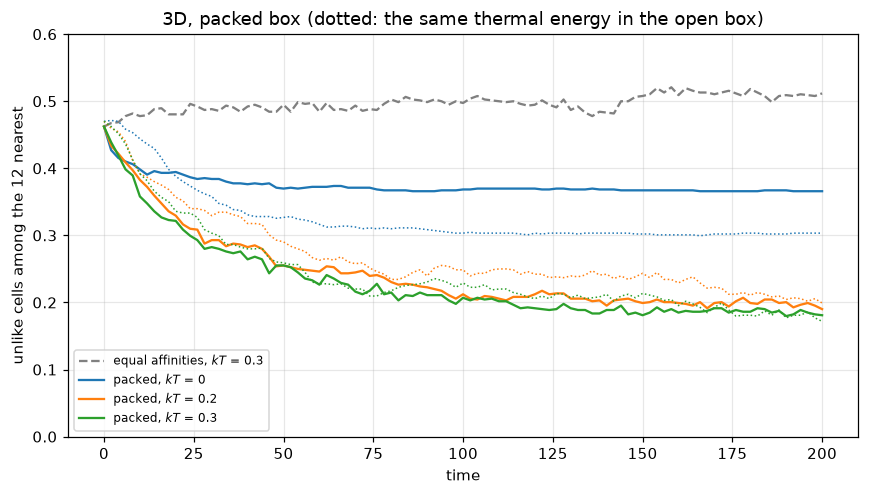

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))

params, packed_control = load("cell_sorting_3d_packed_control.csv")
ax.plot(packed_control["time"], packed_control["unlike_nearest_fraction"], color="gray", linestyle="--", label="equal affinities, $kT$ = 0.3")

print(f"{'thermal energy':<16}{'packed box':>12}{'open box':>10}{'strayed, packed':>17}")
packed = {}
for kT in ("0", "0.2", "0.3"):
    params, table = load(f"cell_sorting_3d_packed_kT_{kT}.csv")
    line, = ax.plot(table["time"], table["unlike_nearest_fraction"], label=f"packed, $kT$ = {kT}")
    _, open_box = load(f"cell_sorting_3d_kT_{kT}.csv")
    ax.plot(open_box["time"], open_box["unlike_nearest_fraction"], color=line.get_color(), linestyle=":", linewidth=1)
    packed[kT] = late(table)
    print(f"{kT:<16}{packed[kT]:>12.2f}{late(open_box):>10.2f}{int(table['stray_elements'][-1]):>17}")
print(f"{'control, 0.3':<16}{late(packed_control):>12.2f}{'':>10}{int(packed_control['stray_elements'][-1]):>17}")

ax.set(xlabel="time", ylabel="unlike cells among the 12 nearest", ylim=(0, 0.6),
       title="3D, packed box (dotted: the same thermal energy in the open box)")
ax.legend(fontsize=8)
fig.tight_layout()

assert late(packed_control) > 0.45, "with equal affinities packed cells stay mixed"
assert packed["0"] > 0.33, "without noise packed cells sort little and then jam"
assert packed["0.2"] < 0.25 and packed["0.3"] < 0.25, "with strong noise packed cells sort"

Packing changes the picture in the way one would hope:

- **Without noise the packed cells sort less** than in the open box and then jam. In the open box part of the
  apparent sorting was cells moving apart.
- **With strong noise they sort as far as in the open box**, here without anywhere to drift to. The contrast
  between no noise and strong noise is therefore larger when packed, and it is the cleaner evidence that
  thermal noise drives the rearrangement.
- **The control does not sort**: with equal affinities and the same noise the measure stays at its mixed value.

## Reading the result

- **The affinity does the sorting.** With equal affinities the measure stays where it started, in 2D and in 3D.
  With a low affinity between the types it falls in every run. Nothing else differs between those runs.
- **Much of the sorting needs no noise.** Without any thermal energy the 3D block still sorts part of the way and
  then freezes: like cells pull together while the block settles from its starting arrangement, and after that
  nothing can move.
- **Noise helps only above a threshold.** $kT$ = 0.05 and 0.1 end where the run without noise ends. At 0.2 and
  0.3 the cells keep rearranging and the measure is still falling at the end of the run.
- **Too much noise costs elements.** At $kT$ = 0.3 a few elements have left their cells for good, and their
  number grows with time. That is the upper limit of the useful range for these parameters.
- **Stiffer cells sort a little less.** The ranking is as expected, 1 before 2 before 4, but the differences are
  small.
- **In 2D with crawling cells the effect is modest**: the measure falls by about a fifth.

### Hints for calibration

- **Start from one type.** Set its `inter_well_depth` (through the adhesion ratio of `scale_to_elements`, 0.5 by
  default) so that two cells adhere without merging; see the two-cells notebook.
- **Then set affinities**, which only weaken attraction. A type's affinity to itself scales how cohesive a
  tissue of that type is; the affinity between two types scales how well they mix.
- **Affinities need not be symmetric in the input.** The value used for a pair is the geometric mean of the two
  entries, so 0.4 one way and 0.1 the other act as 0.2 both ways. If one entry is 0, the pair does not attract.
- **Thermal energy: between about a fifth and a third of the well depth between cells times two**, that is
  0.2 to 0.3 for a contact depth of 0.5 and an intra-cellular depth of 1, lets cells rearrange without losing
  many elements. Check the number of strayed elements for your own parameters.
- **The timestep must shrink with the stiffness.** A well four times deeper is a spring four times faster. Run
  with the timestep of the soft case, the stiffness-4 cells fell apart within 20 time units, a purely numerical
  failure; the example divides its timestep by the stiffness.
- **Different element sizes mix through their radii.** A contact between a coarse and a fine cell rests at the
  sum of the two element radii.

### Caveats

- **One run per setting, one random start.** The trends with affinity and with strong noise are clear. The small
  differences (between $kT$ 0, 0.05 and 0.1, and between the stiffnesses) are of the size one would expect from
  changing the seed, which was not tried.
- **Stiffness and temperature are not independent.** What matters inside a cell is the thermal energy relative
  to its well depth, so raising the stiffness at fixed $kT$ also makes the cell colder inside. These runs cannot
  tell that apart from the cell being harder to deform.
- **The runs are short.** The hot runs are still sorting at the end; none has reached a final state.
- **The measure is not purely topological.** Like cells that pull closer raise their own share among the
  nearest cells a little without any cell changing place.
- **The stiffness of a contact is not the same on its two sides** when the affinity is below 1: compressing it
  meets the full well, stretching it the weakened one.
- **The steepness of the potential is shared by all types**, and elements that belong to no cell interact as if
  they were of the first type.
- **Walls are as hard as a contact with a cell of the element's own type.** A type with `inter_well_depth` 0
  feels neither other cells nor the soft wall; only the hard stop keeps it inside.